<a href="https://colab.research.google.com/github/PhilipeJevoux121/Modelagem-Computacional---Philipe-163971/blob/main/image_predictor_SAM2_Pluma_Philipe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mascaras de objeto em imagens via prompts usando SAM 2

## Configuração do ambiente

In [1]:
using_colab = True

In [7]:
if using_colab:
    import torch
    import torchvision
    print("PyTorch version:", torch.__version__)
    print("Torchvision version:", torchvision.__version__)
    print("CUDA is available:", torch.cuda.is_available())
    import sys
    !{sys.executable} -m pip install opencv-python matplotlib
    !{sys.executable} -m pip install 'git+https://github.com/facebookresearch/sam2.git'

    !mkdir -p images
    !wget -P images https://github.com/PhilipeJevoux121/Modelagem-Computacional---Philipe-163971/blob/main/Pluma1.jpg?raw=true
    !wget -P images https://github.com/PhilipeJevoux121/Modelagem-Computacional---Philipe-163971/blob/main/Pluma2.jpg?raw=true
    !wget -P images https://github.com/PhilipeJevoux121/Modelagem-Computacional---Philipe-163971/blob/main/Pluma3.jpg?raw=true

    !mkdir -p ../checkpoints/
    !wget -P ../checkpoints/ https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_large.pt

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
CUDA is available: True
  Cloning https://github.com/facebookresearch/sam2.git to /tmp/pip-req-build-zskvx9cv
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/sam2.git /tmp/pip-req-build-zskvx9cv
  Resolved https://github.com/facebookresearch/sam2.git to commit 2b90b9f5ceec907a1c18123530e92e794ad901a4
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
--2026-10-20 01:09:00--  https://github.com/PhilipeJevoux121/Modelagem-Computacional---Philipe-163971/blob/main/Pluma1.jpg
Resolving github.com (github.com)... 20.29.134.23
Connecting to github.com (github.com)|20.29.134.23|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified [text/html]
Saving to: ‘images/Pluma1.jpg’

Pluma1.jpg              [ <=>                ] 202.46K  --.-KB/s    in 0.04s   

2026-10-20 01:09:00 (

## Configuração

In [12]:
import os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

In [13]:
# select the device for computation
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"using device: {device}")

if device.type == "cuda":
    # use bfloat16 for the entire notebook
    torch.autocast("cuda", dtype=torch.bfloat16).__enter__()
    # turn on tfloat32 for Ampere GPUs (https://pytorch.org/docs/stable/notes/cuda.html#tensorfloat-32-tf32-on-ampere-devices)
    if torch.cuda.get_device_properties(0).major >= 8:
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
elif device.type == "mps":
    print(
        "\nSupport for MPS devices is preliminary. SAM 2 is trained with CUDA and might "
        "give numerically different outputs and sometimes degraded performance on MPS. "
        "See e.g. https://github.com/pytorch/pytorch/issues/84936 for a discussion."
    )

using device: cuda


In [16]:
np.random.seed(3)

def show_mask(mask, ax, random_color=False, borders = True):
    if random_color:
        color = np.concatenate([np.random.random(3), np.array([0.6])], axis=0)
    else:
        color = np.array([30/255, 144/255, 255/255, 0.6])
    h, w = mask.shape[-2:]
    mask = mask.astype(np.uint8)
    mask_image =  mask.reshape(h, w, 1) * color.reshape(1, 1, -1)
    if borders:
        import cv2
        contours, _ = cv2.findContours(mask,cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        # Try to smooth contours
        contours = [cv2.approxPolyDP(contour, epsilon=0.01, closed=True) for contour in contours]
        mask_image = cv2.drawContours(mask_image, contours, -1, (1, 1, 1, 0.5), thickness=2)
    ax.imshow(mask_image)

def show_points(coords, labels, ax, marker_size=375):
    pos_points = coords[labels==1]
    neg_points = coords[labels==0]
    ax.scatter(pos_points[:, 0], pos_points[:, 1], color='green', marker='*', s=marker_size, edgecolor='white', linewidth=1.25)
    ax.scatter(neg_points[:, 0], neg_points[:, 1], color='red', marker='*', s=marker_size, edgecolor='white', linewidth=1.25)

def show_box(box, ax):
    x0, y0 = box[0], box[1]
    w, h = box[2] - box[0], box[3] - box[1]
    ax.add_patch(plt.Rectangle((x0, y0), w, h, edgecolor='green', facecolor=(0, 0, 0, 0), lw=2))

def show_masks(image, masks, scores, point_coords=None, box_coords=None, input_labels=None, borders=True):
    for i, (mask, score) in enumerate(zip(masks, scores)):
        plt.figure(figsize=(10, 10))
        plt.imshow(image)
        show_mask(mask, plt.gca(), borders=borders)
        if point_coords is not None:
            assert input_labels is not None
            show_points(point_coords, input_labels, plt.gca())
        if box_coords is not None:
            # boxes
            show_box(box_coords, plt.gca())
        if len(scores) > 1:
            plt.title(f"Mask {i+1}, Score: {score:.3f}", fontsize=18)
        plt.axis('off')
        plt.show()

## Primeira imagem
Usando imagem da pluma original enviada pela orientadora

In [20]:
image = Image.open('/content/images/Pluma1.jpg?raw=true')
image = np.array(image.convert("RGB"))

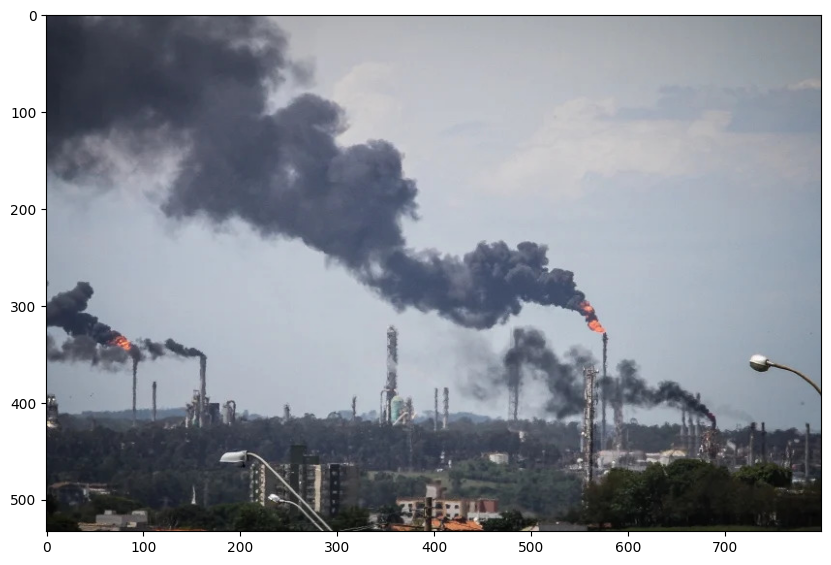

In [21]:
plt.figure(figsize=(10, 10))
plt.imshow(image)
plt.axis('on')
plt.show()

## Selecionando objetos com o SAM 2

In [22]:
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

sam2_checkpoint = "../checkpoints/sam2.1_hiera_large.pt"
model_cfg = "configs/sam2.1/sam2.1_hiera_l.yaml"

sam2_model = build_sam2(model_cfg, sam2_checkpoint, device=device)

predictor = SAM2ImagePredictor(sam2_model)

In [23]:
predictor.set_image(image)

In [26]:
input_point = np.array([[450, 300]])
input_label = np.array([1])

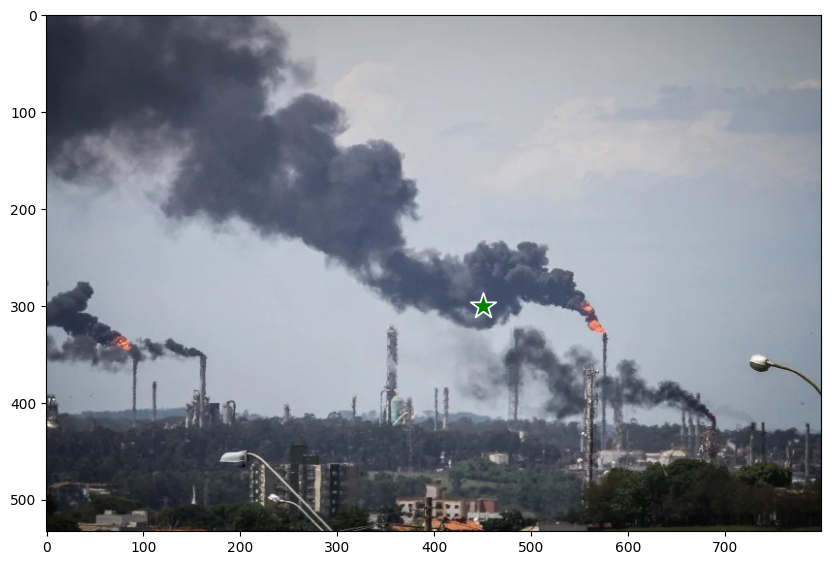

In [27]:
plt.figure(figsize=(10, 10))
plt.imshow(image)
show_points(input_point, input_label, plt.gca())
plt.axis('on')
plt.show()

In [28]:
print(predictor._features["image_embed"].shape, predictor._features["image_embed"][-1].shape)

torch.Size([1, 256, 64, 64]) torch.Size([256, 64, 64])


In [29]:
masks, scores, logits = predictor.predict(
    point_coords=input_point,
    point_labels=input_label,
    multimask_output=True,
)
sorted_ind = np.argsort(scores)[::-1]
masks = masks[sorted_ind]
scores = scores[sorted_ind]
logits = logits[sorted_ind]

In [30]:
masks.shape  # (number_of_masks) x H x W

(3, 533, 800)

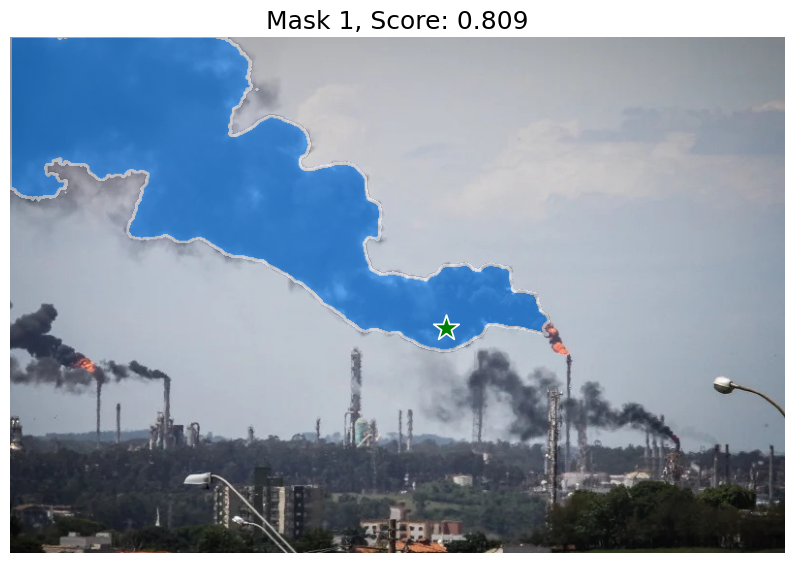

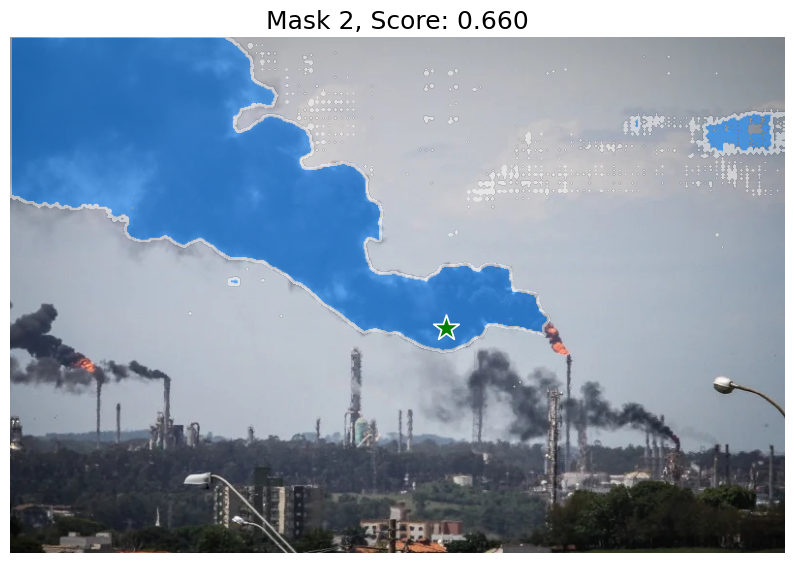

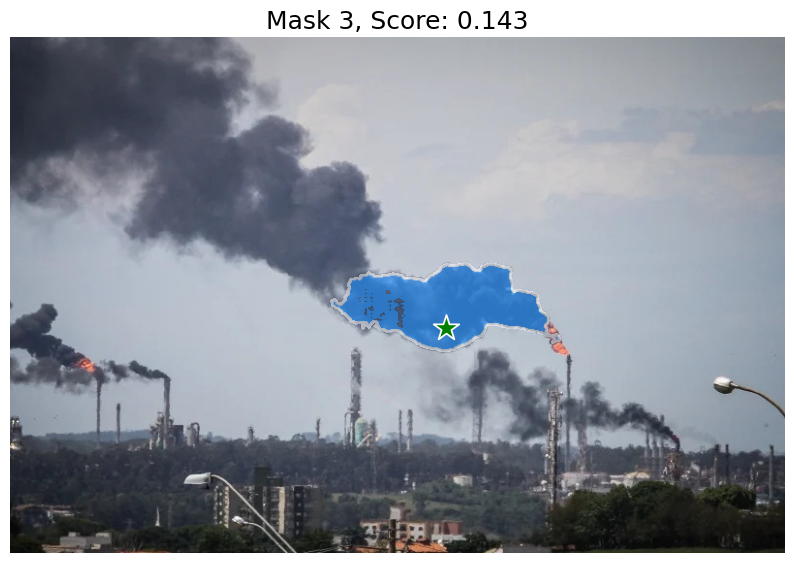

In [31]:
show_masks(image, masks, scores, point_coords=input_point, input_labels=input_label, borders=True)

## Specifying a specific object with additional points

In [40]:
input_point = np.array([[450, 300], [530, 380]])
input_label = np.array([1, 1])

mask_input = logits[np.argmax(scores), :, :]  # Choose the model's best mask

In [37]:
masks, scores, _ = predictor.predict(
    point_coords=input_point,
    point_labels=input_label,
    mask_input=mask_input[None, :, :],
    multimask_output=False,
)

In [38]:
masks.shape

(1, 533, 800)

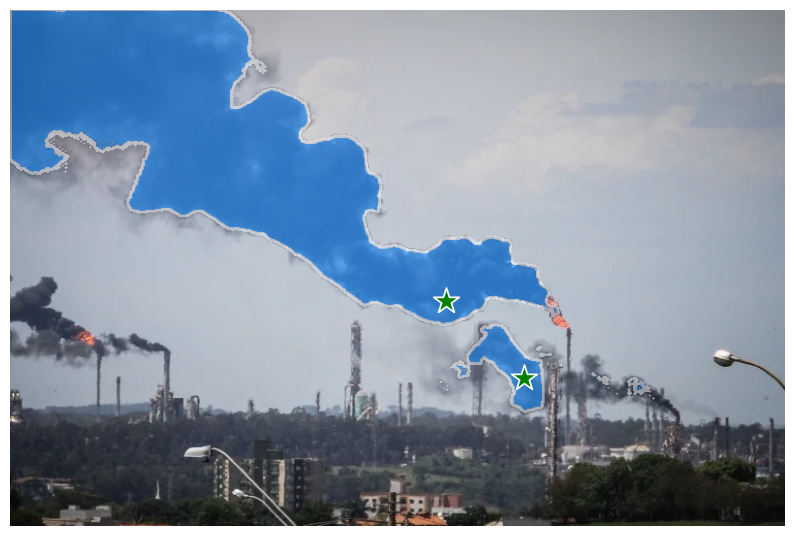

In [41]:
show_masks(image, masks, scores, point_coords=input_point, input_labels=input_label)

In [45]:
input_point = np.array([[450, 300], [530, 380]])
input_label = np.array([1, 0])

mask_input = logits[np.argmax(scores), :, :]

In [43]:
masks, scores, _ = predictor.predict(
    point_coords=input_point,
    point_labels=input_label,
    mask_input=mask_input[None, :, :],
    multimask_output=False,
)

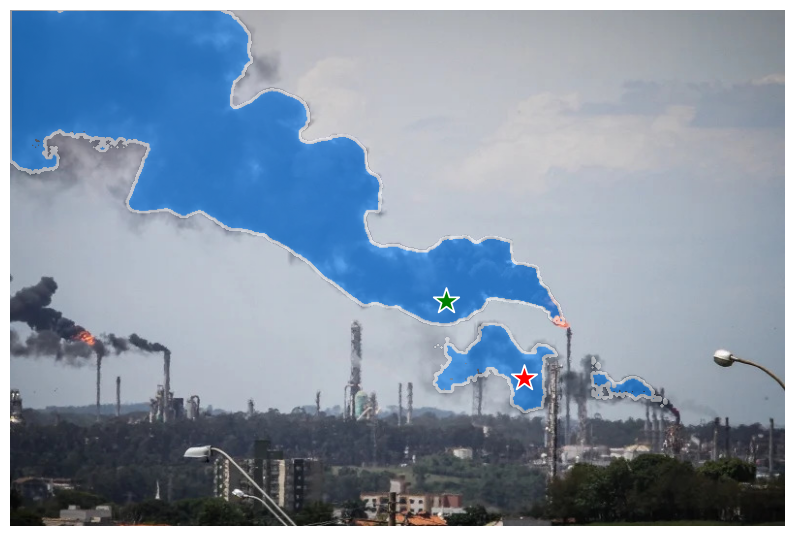

In [46]:
show_masks(image, masks, scores, point_coords=input_point, input_labels=input_label)

## Specifying a specific object with a box

In [104]:
input_box = np.array([0, 0, 500, 400])

In [105]:
masks, scores, _ = predictor.predict(
    point_coords=None,
    point_labels=None,
    box=input_box[None, :],
    multimask_output=False,
)

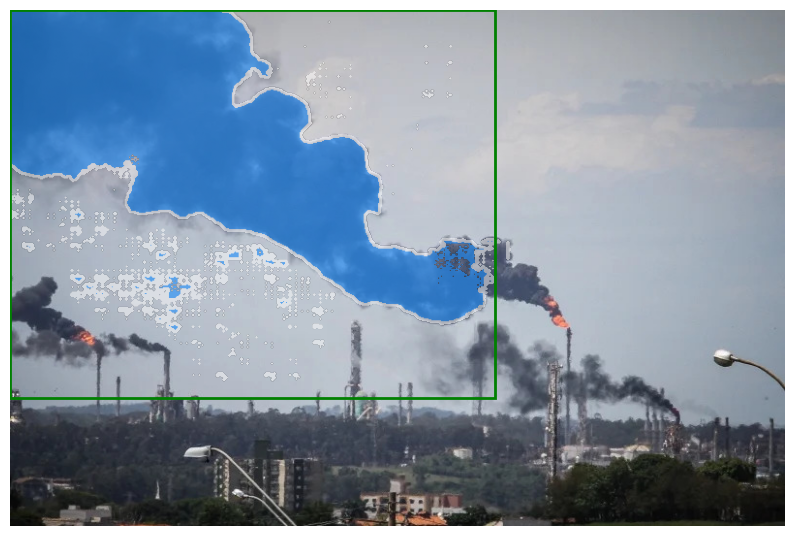

In [106]:
show_masks(image, masks, scores, box_coords=input_box)

## Três imagens com score

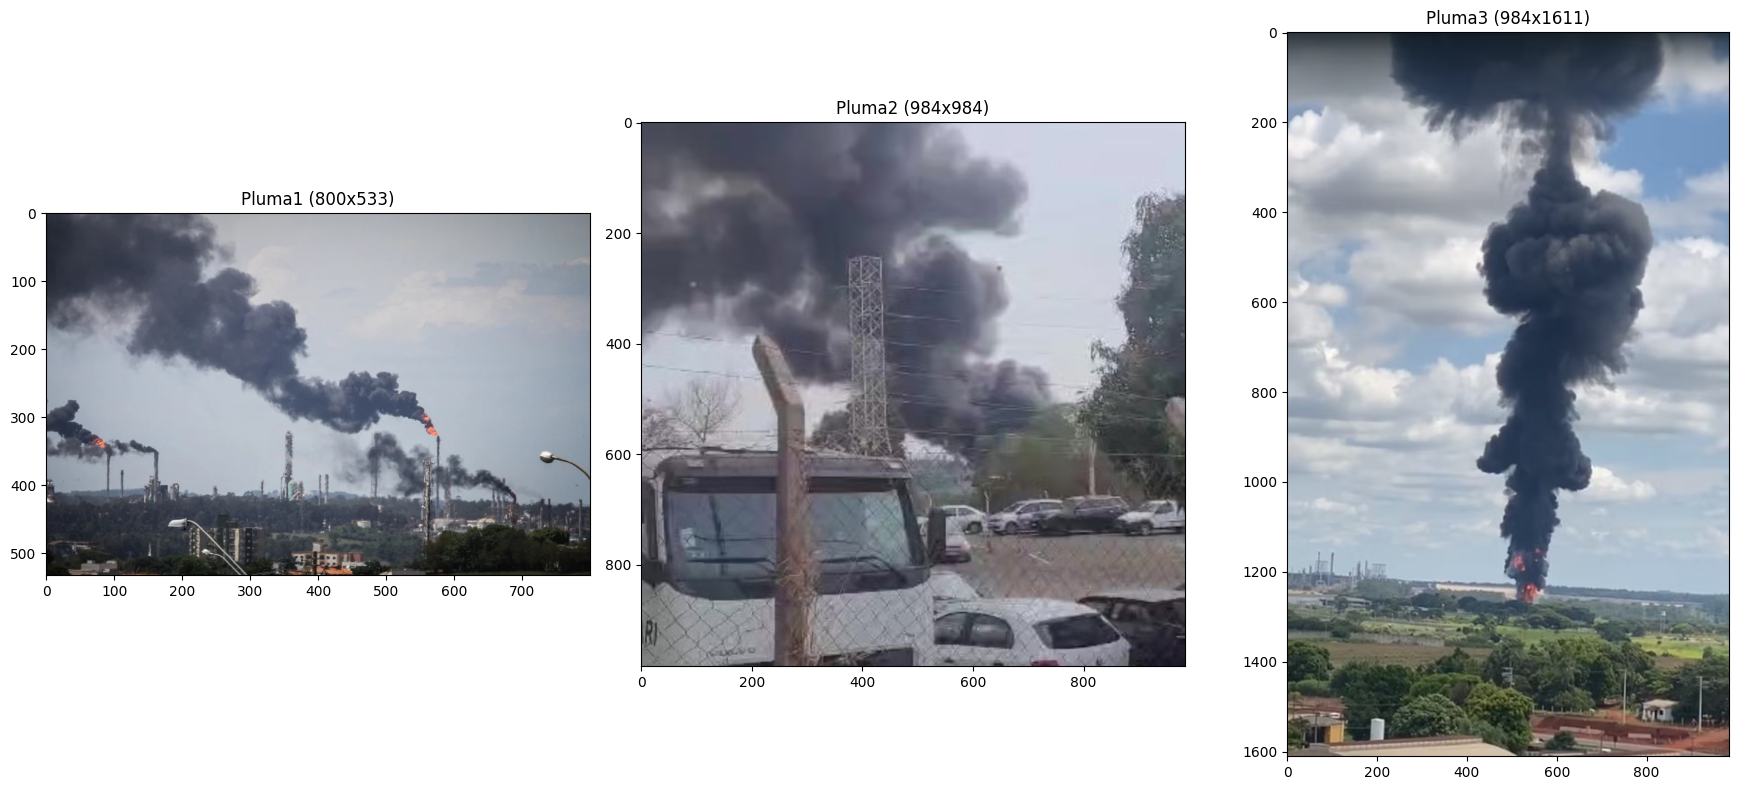

In [138]:
nomes = ["Pluma1", "Pluma2", "Pluma3"]
imagens = {n: np.array(Image.open(f"/content/images/{n}.jpg?raw=true").convert("RGB"))
           for n in nomes}

fig, axs = plt.subplots(1, 3, figsize=(18, 8))
for ax, n in zip(axs, nomes):
    ax.imshow(imagens[n])
    ax.set_title(f"{n} ({imagens[n].shape[1]}x{imagens[n].shape[0]})")
    ax.axis("on")
plt.tight_layout()
plt.show()

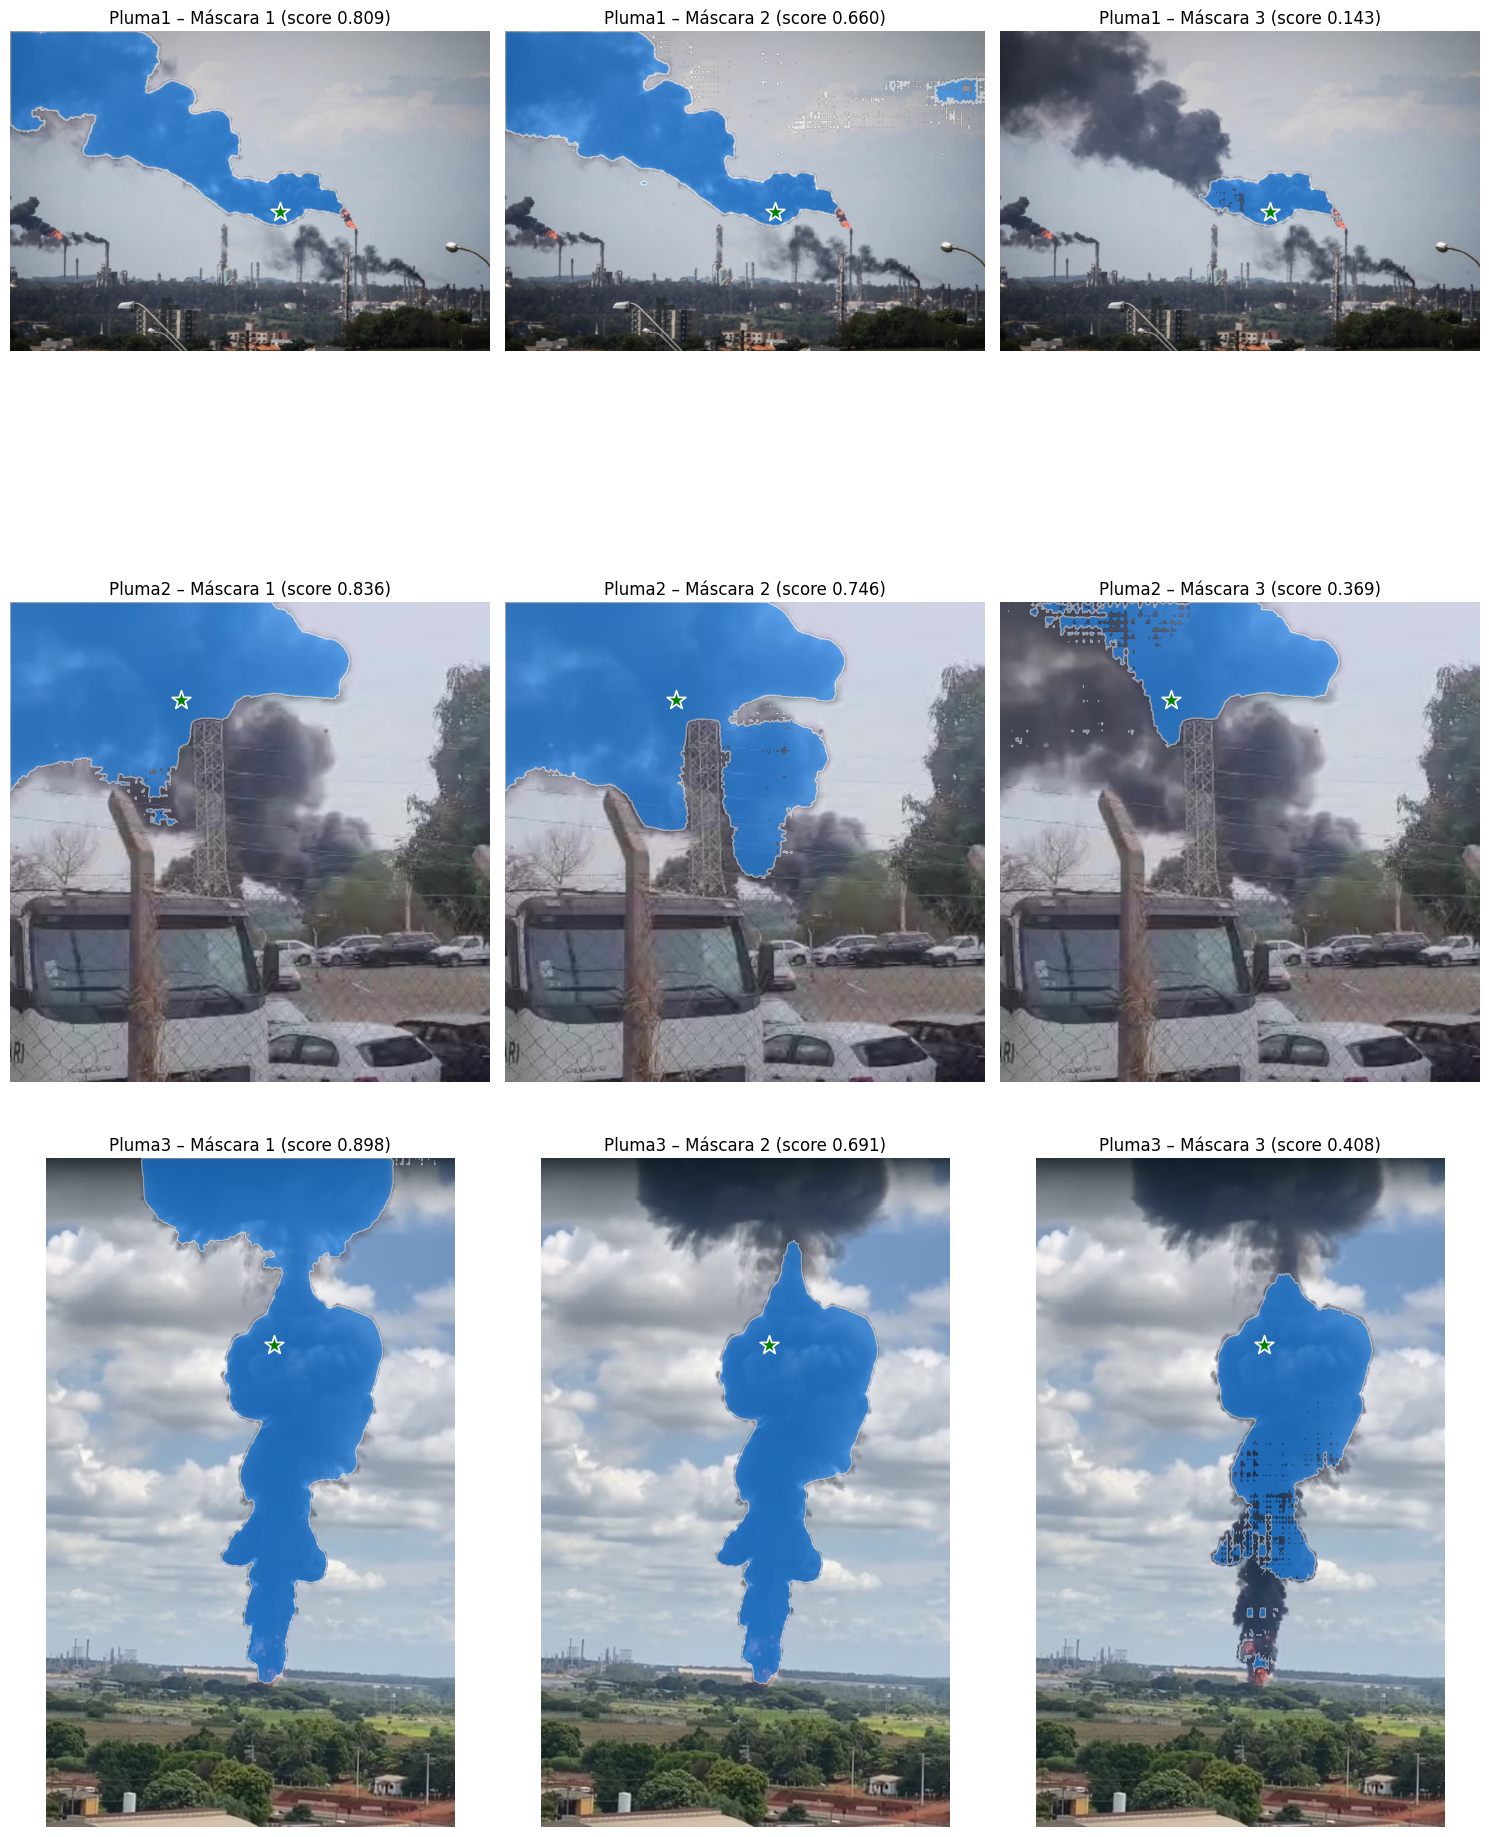

In [141]:
pontos = {
    "Pluma1": [450, 300],
    "Pluma2": [350, 200],
    "Pluma3": [550, 450],
}

def tres_mascaras(img, ponto):
    predictor.set_image(img)
    masks, scores, _ = predictor.predict(
        point_coords=np.array([ponto]),
        point_labels=np.array([1]),
        multimask_output=True,
    )
    ordem = np.argsort(scores)[::-1]
    return masks[ordem], scores[ordem]

fig, axs = plt.subplots(3, 3, figsize=(15, 20))
for i, n in enumerate(nomes):
    img = imagens[n]
    h, w = img.shape[:2]
    ponto = pontos.get(n)
    if ponto is None:
        ponto = [w // 2, h // 2]
        print(f"Aviso: {n} sem ponto definido, usando o centro {ponto}")
    masks, scores = tres_mascaras(img, ponto)
    for j in range(3):
        ax = axs[i, j]
        ax.imshow(img)
        show_mask(masks[j], ax, borders=True)
        show_points(np.array([ponto]), np.array([1]), ax, marker_size=200)
        ax.set_title(f"{n} – Máscara {j+1} (score {scores[j]:.3f})", fontsize=12)
        ax.axis("off")

plt.tight_layout()
plt.savefig("/content/scores_3x3.png", dpi=150, bbox_inches="tight")
plt.show()

## Resultados:

Com um único ponto positivo, o SAM 2 devolveu três máscaras por imagem, e a de maior score nem sempre foi a mais útil. Na Pluma3, a máscara 1 (score 0,898) cobre a coluna de fumaça inteira, do topo escuro até a base, praticamente sem vazar para as nuvens brancas ao redor, enquanto as máscaras 2 (0,691) e 3 (0,408) deixam de fora o topo e a base, o que mostra que o modelo trata partes da pluma como objetos distintos e que um ponto sozinho é ambíguo. Na Pluma1, a máscara 1 (0,809) acompanha o braço principal da pluma até a chama, mas não inclui as demais colunas de fumaça da refinaria; a máscara 2 (0,660) apresenta falhas pontilhadas nas áreas de fumaça fina e um trecho isolado de céu no canto superior direito, região que não pertence à pluma; e a máscara 3 (0,143) fica restrita ao trecho próximo do ponto, omitindo a maior parte da fumaça escura. A Pluma2 foi o pior caso: as máscaras 1 (0,836) e 3 (0,369) seguem a região superior, clara e difusa, onde a fumaça se mistura ao céu, e deixam de fora o núcleo escuro e denso atrás da torre, que só é parcialmente alcançado pela máscara 2 (0,746). Nesse caso, o maior score correspondeu a uma máscara que não representa bem a fumaça densa.

As características das imagens explicam essas diferenças. O contraste foi o fator mais importante: na Pluma3, a fumaça escura contra o céu azul e as nuvens brancas tem bordas bem definidas e gerou o melhor resultado; já na Pluma1 e na Pluma2, a diferença de tom entre fumaça e fundo é pequena e os limites ficam incertos. A iluminação dessas duas imagens achata os tons e reduz esse contraste ainda mais, enquanto a luz direta da Pluma3 realça o contorno da coluna. A semelhança entre fumaça e nuvens também pesa: ambas têm bordas macias, sem limite nítido, e a fumaça é translúcida, deixando o fundo aparecer através dela, o que produziu os “buracos” pontilhados nas máscaras de menor score. Além disso, na Pluma2, a torre, a cerca, os fios, os veículos e as árvores fragmentam e ocultam a pluma, e, na Pluma1, a presença de várias colunas de fumaça torna ambíguo qual delas o ponto indica. Esses resultados indicam que o prompt precisa ser refinado para levar em consideração os nuances de cada pluma, como os formatos das nuvens, a luminosidade das imagens e os objetos presentes à frente da fumaça. Uma ideia seria combinar caixa delimitadora e pontos negativos no céu e nas nuvens, e que a máscara deve ser escolhida por inspeção visual e não apenas pelo score.